# 04 · Logistic Regression

The readable model: its coefficients become **odds ratios** that explain *why* an attempt is likely to be made or missed.

- Regularisation strength `C` tuned with `GridSearchCV` over `StratifiedKFold` (lessons 12, 13), scored on ROC-AUC
- Imbalance options are compared in notebook 06; here the model is trained on the real 75 / 25 balance

In [1]:
import sys, os
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from clean import load_attempts
from prep import split, tune_sample, linear_preprocessor, evaluate, save_result, RANDOM_STATE

sns.set_theme(style='whitegrid')
attempts = load_attempts()
X_train, X_test, y_train, y_test = split(attempts)
del attempts
print('train', X_train.shape, f'make rate {y_train.mean():.1%}')
print('test ', X_test.shape, f'make rate {y_test.mean():.1%}')

train (300000, 22) make rate 74.4%
test  (200000, 22) make rate 78.1%


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

pipe = Pipeline([
    ('prep', linear_preprocessor()),
    ('model', LogisticRegression(max_iter=2000)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(pipe, {'model__C': [0.001, 0.01, 0.1, 1, 10]}, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

print('best C:', grid.best_params_['model__C'], '| CV ROC-AUC:', round(grid.best_score_, 4))
pd.DataFrame(grid.cv_results_)[['param_model__C', 'mean_test_score', 'std_test_score']].round(4)

best C: 10 | CV ROC-AUC: 0.7642


,param_model__C,mean_test_score,std_test_score
0,0.001,0.7627,0.0013
1,0.010,0.7640,0.0014
2,0.100,0.7642,0.0015
3,1.000,0.7642,0.0015
4,10.000,0.7642,0.0015


The cross-validated ROC-AUC is flat (0.764) from `C = 0.1` upward: with 300,000 rows and 61 inputs, regularisation barely matters.
Only very strong regularisation (`C = 0.001`) costs a little (0.763).

## 1. Test-set evaluation (threshold 0.5)

In [3]:
lr = grid.best_estimator_
proba_lr = lr.predict_proba(X_test)[:, 1]
save_result(evaluate('Logistic Regression', y_test, proba_lr))

,model,threshold,accuracy,balanced_accuracy,precision_made,recall_made,precision_missed,recall_missed,f1_missed,roc_auc
0,Baseline (always made),0.5,0.7807,0.5000,0.7807,1.0000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.5,0.7925,0.5869,0.8132,0.9531,0.5693,0.2208,0.3182,0.7635


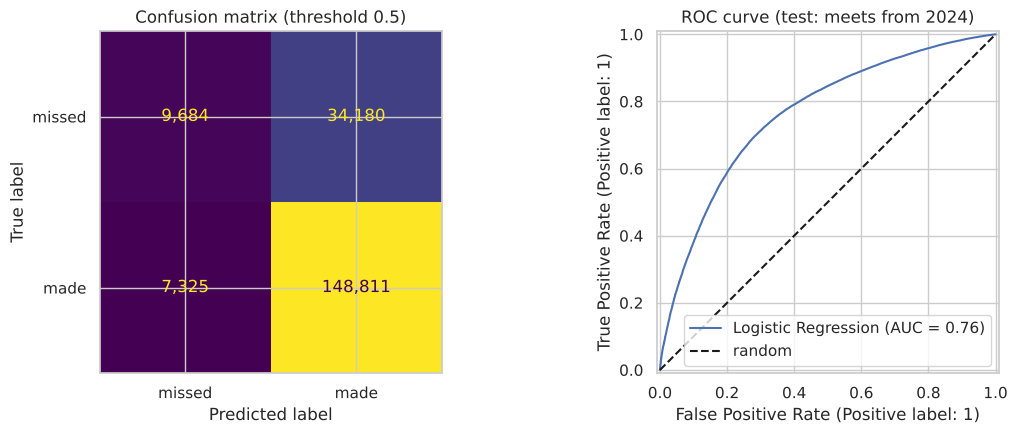

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_lr >= 0.5).astype(int), display_labels=['missed', 'made'],
                                        ax=axes[0], colorbar=False, values_format=',')
axes[0].set_title('Confusion matrix (threshold 0.5)')
RocCurveDisplay.from_predictions(y_test, proba_lr, ax=axes[1], name='Logistic Regression')
axes[1].plot([0, 1], [0, 1], 'k--', label='random')
axes[1].set_title('ROC curve (test: meets from 2024)'); axes[1].legend()
plt.tight_layout(); plt.show()

- **ROC-AUC 0.764** on meets from 2024 (baseline 0.50), almost the same as in cross-validation (0.764), so the model holds up on future meets.
- At the default 0.5 threshold it warns about only **22%** of the misses (recall for missed), but **57%** of its warnings are real misses (precision), against 22% for random warnings.
- Most attempts get a probability above 0.5, because most attempts are made. The threshold is tuned in notebook 07.

## 2. Odds ratios: what drives a made attempt?

Numeric features were scaled, so their odds ratio is per one standard deviation. One-hot features are compared with the dropped reference category
(lift = Bench, prev_result = made, attempt_no = 1, pct_best_bin = 100–102.5, jump_bin = 0–2.5, Equipment = Raw, Sex = F, Event = B, tested = No, meet_country = Australia).
An odds ratio above 1 raises the chance of a make; below 1 lowers it.

In [5]:
names = lr.named_steps['prep'].get_feature_names_out()
coefs = lr.named_steps['model'].coef_[0]
odds = (pd.DataFrame({'feature': names, 'coef': coefs, 'odds_ratio': np.exp(coefs)})
        .sort_values('coef', ascending=False).reset_index(drop=True))
pd.concat([odds.head(12), odds.tail(12)]).round(3)

,feature,coef,odds_ratio
0,lift_Deadlift,1.199,3.317
1,prev_result_unknown,0.777,2.175
2,jump_bin_unknown,0.777,2.175
3,jump_bin_first attempt,0.489,1.631
4,prev_result_none,0.489,1.631
5,pct_best_bin_85-90,0.488,1.629
6,pct_best_bin_<85,0.453,1.573
7,lift_Squat,0.444,1.559
8,pct_best_bin_90-95,0.435,1.545
9,Event_SBD,0.288,1.334


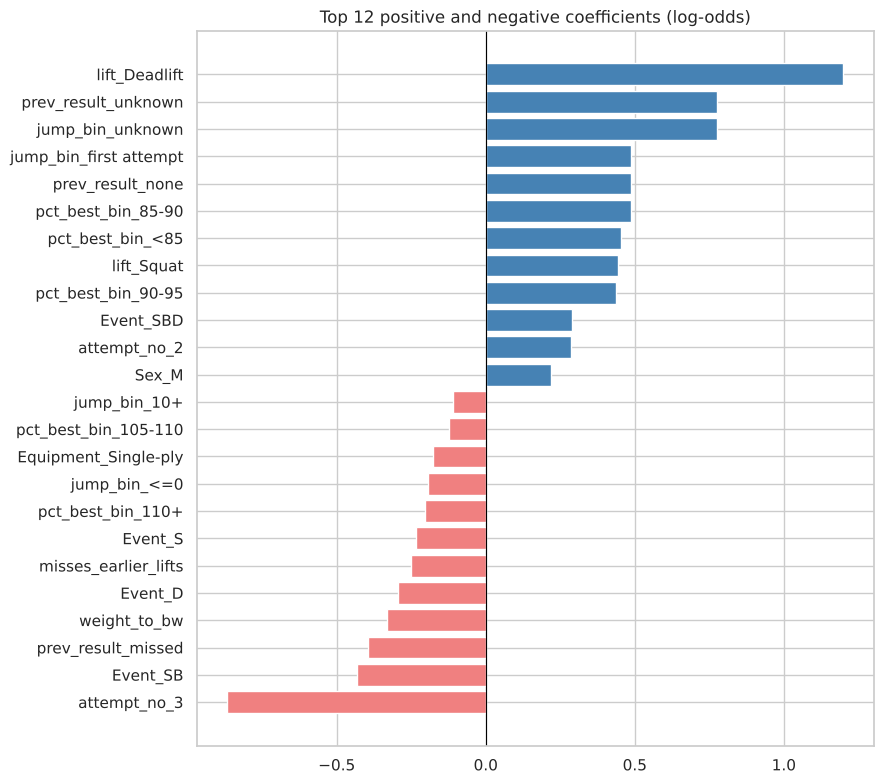

In [6]:
top = pd.concat([odds.head(12), odds.tail(12)])
plt.figure(figsize=(9, 8))
plt.barh(top['feature'], top['coef'], color=np.where(top['coef'] > 0, 'steelblue', 'lightcoral'))
plt.axvline(0, color='black', lw=0.8)
plt.gca().invert_yaxis()
plt.title('Top 12 positive and negative coefficients (log-odds)')
plt.tight_layout(); plt.show()

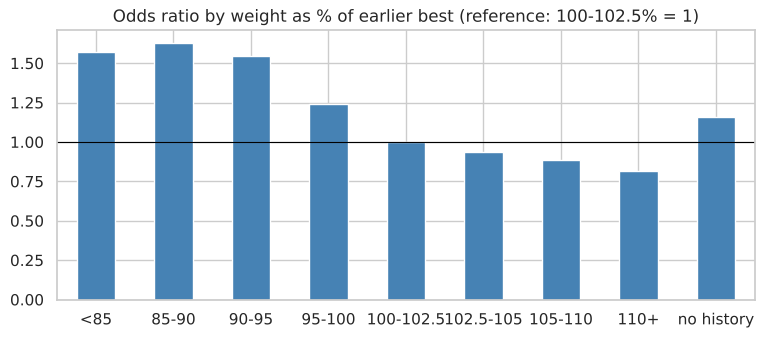

<85           1.57
85-90         1.63
90-95         1.55
95-100        1.24
100-102.5     1.00
102.5-105     0.94
105-110       0.88
110+          0.82
no history    1.16
Name: odds_ratio, dtype: float64

In [7]:
bins_order = ['<85', '85-90', '90-95', '95-100', '100-102.5', '102.5-105', '105-110', '110+', 'no history']
pb = odds.set_index('feature')['odds_ratio'].reindex([f'pct_best_bin_{b}' for b in bins_order]).fillna(1.0)
pb.index = bins_order
pb.plot(kind='bar', color='steelblue', figsize=(9, 3.5), rot=0)
plt.axhline(1, color='black', lw=0.8)
plt.title('Odds ratio by weight as % of earlier best (reference: 100-102.5% = 1)')
plt.show()
pb.round(2)

Reading the odds ratios (holding everything else equal):

- **Third attempt:** odds × **0.42** compared with the opener; second attempt × 1.33 (most second attempts follow a made opener).
- **Lift:** deadlift odds × **3.32** and squat × 1.56 compared with the bench press, the hardest lift to make.
- **Previous attempt missed:** odds × **0.68** compared with a made previous attempt.
- **Weight vs earlier best:** 85–90% of the earlier best × **1.63** compared with 100–102.5%; above 110% × 0.82. The odds fall step by step as the weight climbs past the old best, the same shape as in the EDA.
- **Weight ÷ bodyweight:** each extra standard deviation (about 0.7× bodyweight) × 0.72.
- **Misses on earlier lifts:** each standard deviation (about one miss) × 0.78: a bad day carries over.
- **Single-ply** × 0.84 vs raw; bench-only and squat-only meets lower than full power (Event_SBD × 1.33 vs bench-only).

`prev_result_none`, `jump_bin_first attempt` and `attempt_no_1` describe the same rows (openers), so their effect is shared between them; the same holds for the rare `unknown` level (0.08% of attempts).
These match the EDA, which is a good sign the model learned real patterns.

In [8]:
os.makedirs('../results', exist_ok=True)
pd.DataFrame({'y_true': y_test.values, 'logistic_regression': proba_lr.round(5)}).to_csv('../results/test_probas.csv', index=False)
odds.round(4).to_csv('../results/lr_odds_ratios.csv', index=False)